# 02 - Modeling
Perbandingan beberapa model non-neural-network di dalam **Pipeline + ColumnTransformer**, pada subset 20% data (hanya untuk perbandingan cepat). Model final dilatih penuh lewat `scripts/train.py`.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
sys.path.insert(0, str(Path.cwd().parent))  # agar `scripts` bisa di-import dari folder notebooks/
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scripts.config import *
from scripts.preprocess import load_data, encode_target
sns.set_theme(style='whitegrid')
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from lightgbm import LGBMClassifier
from scripts.feature_engineering import BuildingFeatureAdder
from scripts.preprocess import build_preprocessor, DERIVED_NUM
from scripts.models import build_pipeline
from scripts.neighbor_features import NeighborTargetFeatures

train, _ = load_data()
sub = train.sample(frac=0.2, random_state=SEED)
X, y = sub.drop(columns=[TARGET]), encode_target(sub[TARGET])
Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

## Baseline linear (OvR dan OvO) dengan one-hot + scaling
Sesuai materi multiclass: One-vs-Rest dan One-vs-One dengan Logistic Regression.

In [2]:
def linear_pre():
    num = NUM_COLS + DERIVED_NUM
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), CAT_COLS + GEO_COLS),
    ])
def lin(strategy):
    return Pipeline([('fe', BuildingFeatureAdder(use_serial=False)), ('pre', linear_pre()),
                     ('clf', strategy(LogisticRegression(max_iter=300, C=1.0)))])
def tree_pipe(clf):
    return Pipeline([('nbr', NeighborTargetFeatures()), ('fe', BuildingFeatureAdder(use_serial=False)),
                     ('pre', build_preprocessor(False)), ('clf', clf)])
models = {
    'Logistic OvR': lin(OneVsRestClassifier),
    'Logistic OvO': lin(OneVsOneClassifier),
    'Random Forest': tree_pipe(RandomForestClassifier(300, min_samples_leaf=3, n_jobs=-1, random_state=SEED)),
    'HistGradientBoosting': tree_pipe(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEED)),
    'LightGBM tanpa fitur tetangga': build_pipeline(use_neighbors=False, n_estimators=300),
    'LightGBM (final)': build_pipeline(n_estimators=300),
}
rows = []
for name, m in models.items():
    m.fit(Xa, ya); p = m.predict(Xb)
    rows.append(dict(model=name, accuracy=accuracy_score(yb,p), macro_f1=f1_score(yb,p,average='macro'),
                     qwk=cohen_kappa_score(yb,p,weights='quadratic')))
res = pd.DataFrame(rows).set_index('model').round(4).sort_values('accuracy', ascending=False)
res

,accuracy,macro_f1,qwk
model,,,
LightGBM (final),0.5806,0.5426,0.7235
HistGradientBoosting,0.5770,0.5371,0.7221
Random Forest,0.5752,0.5330,0.7120
LightGBM tanpa fitur tetangga,0.5593,0.5143,0.7070
Logistic OvO,0.5510,0.4992,0.6943
Logistic OvR,0.5499,0.4955,0.6908


Perbandingan di subset kecil (sekitar 80 ribu baris, satu split). Model pohon memakai fitur tetangga `building_id`; model linear OvR/OvO tidak. **LightGBM (final)** unggul tipis atas HistGradientBoosting dan Random Forest, dan tanpa fitur tetangga LightGBM turun sekitar 2 poin akurasi pada subset ini. Pada seluruh data selisihnya lebih besar (holdout 0.6224 vs 0.5845) karena label tetangga lebih rapat. Selisih antar model pohon kecil dan belum tentu signifikan pada satu split.

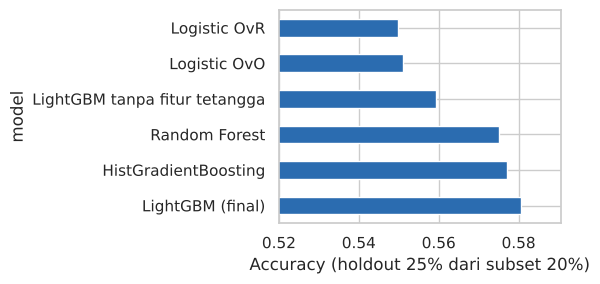

In [3]:
res.accuracy.plot.barh(color='#2b6cb0', figsize=(6,3)); plt.xlabel('Accuracy (holdout 25% dari subset 20%)'); plt.xlim(res.accuracy.min()-0.03, res.accuracy.max()+0.01); plt.tight_layout(); plt.show()

## Hasil model final
Metrik holdout 20% dicetak oleh `python -m scripts.train` (Stratified 5-fold CV lewat `python -m scripts.train --cv`), dan figur disimpan di `reports/figures/`. Confusion matrix di bawah dibuat dari prediksi berbobot kelas pada holdout.

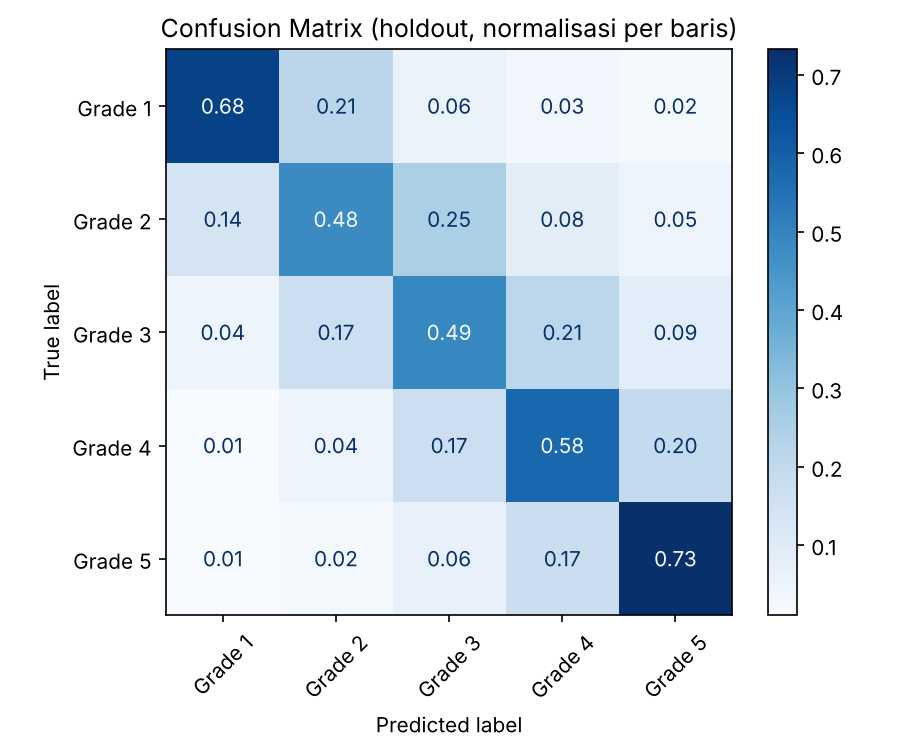

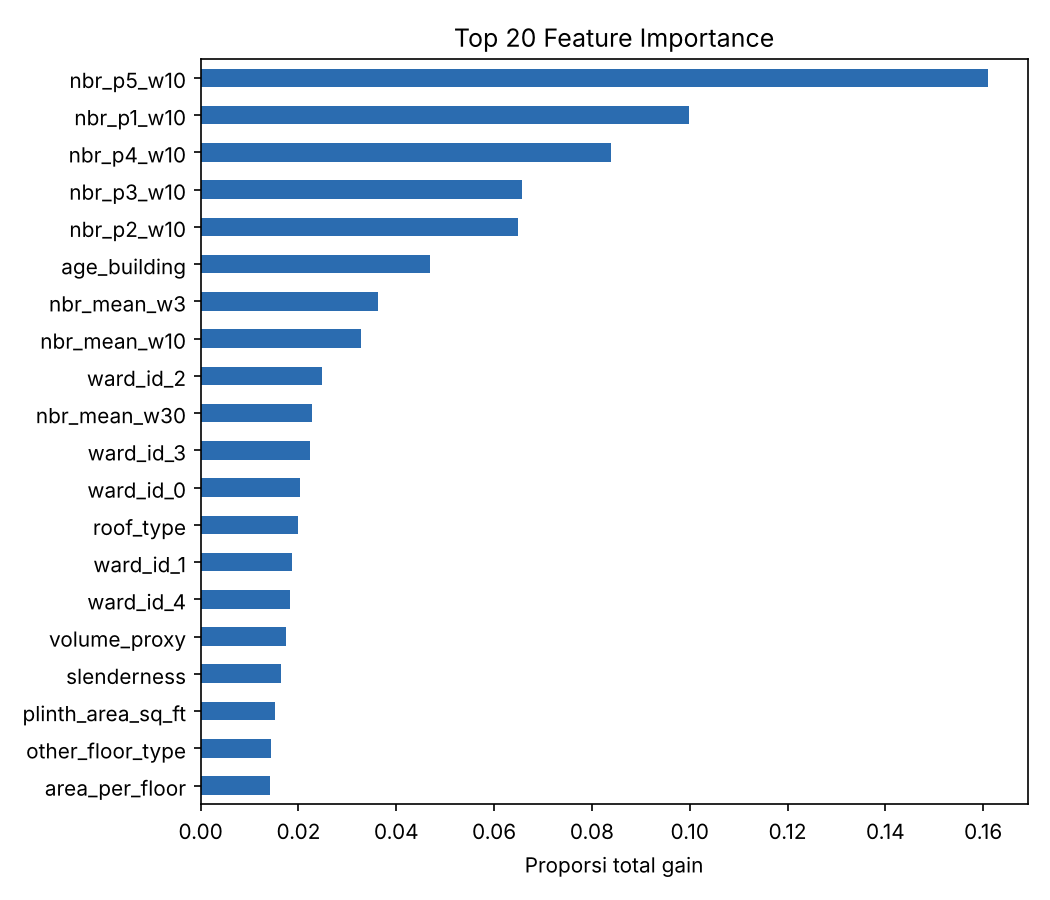

In [4]:
from IPython.display import Image, display
display(Image(FIG_DIR/'confusion_matrix.png', width=420)); display(Image(FIG_DIR/'feature_importance.png', width=520))